# Reverse stress testing: the most likely scenario that breaks a threshold

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 04 and 05 of this topic (the scenarios, the satellites and the capital plan)
- **Reading time:** about 45 minutes

## Objectives

By the end of this notebook you can:

- state what a reverse stress test asks (which plausible scenario would take the bank to a pre-defined failure) and the formal statement the case uses, a minimum Mahalanobis distance problem;
- compute the failure point of the case, the Chilean legal minimum capital stack, and the loss that reaches it;
- write the loss of the bank as a function of two macro factors with the engine's satellites, linearise it, and solve the linear problem in closed form with `reverse_stress_linear`;
- solve the real, nonlinear problem with `reverse_stress` from several starts, read the scenario, its distance and its plausibility, and check the solution with the engine's `reverse_solution_check`;
- say how severe the scenario that breaks the bank is next to the Federal Reserve's and to the global financial crisis, and what that says about the stress test.

## Setup

Install the pinned notebook environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or install only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds the whole environment, `.venv-notebooks`, for you. A notebook never installs anything by itself. The engine's test identifiers are printed as the engine writes them. Its messages and notes are written in English: this tree prints them as written, and the Spanish tree prints a translation from a table in the notebook that fails if the engine changes the text.

The next cell imports what the notebook uses and prints the versions of the packages, so that you can compare them with the pins.

In [1]:
# Import the engine and the helpers, and print the versions of the packages this notebook uses
import importlib.metadata as md
import json
from pathlib import Path

import numpy as np
import riskvalidation as rv
import matplotlib.pyplot as plt
from scipy import stats
from riskvalidation.stress import capital, reverse, satellites
from riskvalidation.validation import stress as stress_tests
for name in ("riskvalidation", "numpy", "scipy", "matplotlib",):
    print(name, md.version(name))

riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

This notebook reads the reverse-stress variant of **C18** (Banco Andino) and the pieces of the baseline that its loss is built from.

- **Owner and licence:** the documents are written by this repository's offline pipeline (`data-pipeline/pipeline/cases/c18/`) with the engine `riskvalidation` and committed under `data/derived/C18/`. The scenario paths come from the Federal Reserve (public domain), the EBA and ESRB (reproduction authorised with the source acknowledged) and the NGFS (derived-only: only the few variables the case uses). **Banco Andino is a synthetic bank**: its book and capital are calibrated to public aggregates, and the scenario paths are real United States and euro-area paths transposed onto its jump-off, so the satellites are a US-calibrated adaptation.
- **Truth status:** `synthetic-calibrated`. There is no answer key for the bank; the checks of this notebook are recomputations of committed numbers with the engine, not comparisons with a published result.
- **Baked by:** `riskvalidation` 0.8.1 (seed 42), the version this notebook installs, so a recomputation is expected to match to rounding.
- **Files read:** `data/derived/C18/reverse-stress.json` (the failure point, the factor space, the committed solution and its four starts), `baseline.json` (the baseline path, the capital at the jump-off, the baseline PPNR and expected losses, the exposure of each loan class, the back-cast rates), `models-banco-andino.json` (the satellite coefficients) and `fed-2026-severely-adverse.json` (the severity rows that compare the scenario with the global financial crisis).
- **Banco Andino's thresholds are conventions.** The failure point, CET1 at the legal minimum stack, is the case's formulation and **not regulatory text**; the CET1 share of Pillar 2 in that stack is a stated assumption (0.0625 percent of RWA).

In [2]:
# The notebook sits three folders below the repository root; a missing file stops the notebook and names its path
ROOT = Path("../../..").resolve()
DERIVED = ROOT / "data" / "derived"


def read_json(relative):
    return json.loads((DERIVED / relative).read_text(encoding="utf-8"))


print("derived folder found:", DERIVED.is_dir())

baseline = read_json("C18/baseline.json")["outputs"]
reverse_doc = read_json("C18/reverse-stress.json")
solution_doc = reverse_doc["outputs"]
models = read_json("C18/models-banco-andino.json")["fit"]
fed = read_json("C18/fed-2026-severely-adverse.json")["outputs"]
print("kind:", solution_doc["kind"], "| loss model:", solution_doc["loss_model"]["kind"], "| baked by riskvalidation", reverse_doc["provenance"]["riskvalidation_version"], "| installed", rv.__version__)

derived folder found: True
kind: reverse | loss model: nonlinear | baked by riskvalidation 0.9.0 | installed 0.9.0


## Method

### Step 1: the question and its formal statement

A stress test starts from a scenario and asks what happens. A **reverse stress test** starts from an outcome and asks which scenarios cause it: the European guideline EBA/GL/2018/04 defines it as one that begins with a pre-defined outcome and explores the scenarios that might lead to it (dossier 01, J.4). The formal statement is Contraste's, not regulatory text. For a loss $L(x)$ as a function of the **deviation $x$ of the macro factors from their baseline**, with factor covariance $\Sigma$, the most plausible scenario that reaches a loss threshold $\ell$ is the one of **highest density** among those that do, which for Gaussian (and elliptical) factors is the one of **minimum Mahalanobis distance**:

$$x^{*} = \arg\min_x\; x^{\top}\Sigma^{-1}x \quad\text{subject to}\quad L(x) \ge \ell, \qquad d^{*} = \sqrt{x^{*\top}\Sigma^{-1}x^{*}}.$$

The attribution of this elliptical result to a specific paper is UNVERIFIED in the dossier (05, H.5); Glasserman, Kang and Kang (2015) estimate the most likely scenarios given large losses by empirical likelihood instead, which the engine does not implement. For a **linear loss** $L(x) = g^{\top}x$ the problem has a closed form,

$$x^{*} = \frac{\Sigma g\,\ell}{g^{\top}\Sigma g}, \qquad d^{*} = \frac{\ell}{\sqrt{g^{\top}\Sigma g}},$$

and otherwise it is solved numerically. The **plausibility** of a solution is $P(\chi^2_k \ge d^{*2})$ with $k$ the number of factors: how often a scenario at least that far from the baseline happens under the factor model.

The next cell reads the committed solution's labels and the failure point, and recomputes the loss threshold of the case: the **headroom of CET1 over the Chilean legal minimum stack** at the jump-off, in CLP millions. The stack is $4.5\% + 2.5\% + \text{CCyB} + c_{\mathrm{DSIB}} + $ the CET1 share of Pillar 2, computed by the engine (notebook 05).

In [3]:
# Read the failure point, recompute the stack with the engine and the loss threshold: headroom of CET1 over the stack, in CLP millions
failure = solution_doc["failure_point"]
start = baseline["capital_start"]
stack = capital.chilean_cet1_stack(failure["stack"]["c_ccyb"], failure["stack"]["c_dsib"], failure["stack"]["p2_cet1"]["value"])
threshold = (start["cet1_ratio"] - stack) * start["rwa_clp_m"]
print("failure point label:", failure["label"], "| horizon (years):", failure["horizon_years"])
print("stack = 4.5% + 2.5% + CCyB + c_DSIB + CET1 share of Pillar 2:", round(stack, 6), "| committed:", failure["stack"]["total"])
print("CET1 ratio at the jump-off:", start["cet1_ratio"], "| RWA:", round(start["rwa_clp_m"], 1))
print("headroom over the stack, CLP millions:", round(threshold, 4), "| committed loss threshold:", round(solution_doc["solution"]["loss_threshold_clp_m"], 4))

failure point label: contraste-formulation-not-regulatory | horizon (years): 3
stack = 4.5% + 2.5% + CCyB + c_DSIB + CET1 share of Pillar 2: 0.090625 | committed: 0.09062500000000001
CET1 ratio at the jump-off: 0.11 | RWA: 7492853.0
headroom over the stack, CLP millions: 145174.0275 | committed loss threshold: 145174.0275


### Step 2: the factors

The two factors are real GDP growth and the unemployment rate, the regressors of the satellites, and their joint behaviour is the sample covariance of 1985 to 2019, the fit window of the satellites. A scenario here is a **persistent deviation** of both factors from the Federal Reserve baseline path, the same deviation in every one of the twelve quarters. The engine validates the covariance before use (symmetric and positive definite) and refuses otherwise. The next cell prints the committed covariance, the standard deviations and the correlation, and shows `reverse_stress_linear` refusing a covariance that is not positive definite.

In [4]:
# Print the factor covariance, its standard deviations and correlation, and show a non-positive-definite covariance being refused
space = solution_doc["factor_space"]
cov = np.array(space["covariance"])
sd = np.array([f["sd"] for f in space["factors"]])
print("factors:", [f["id"] for f in space["factors"]], "| window:", space["window"]["start"], "to", space["window"]["end"], "| label:", space["label"])
print("covariance:", np.round(cov, 4).tolist(), "| sd:", np.round(sd, 4), "| correlation:", round(float(cov[0, 1] / (sd[0] * sd[1])), 4))
try:
    reverse.reverse_stress_linear(np.array([1.0, 1.0]), np.array([[1.0, 2.0], [2.0, 1.0]]), 1.0)
except ValueError as err:
    print("a covariance that is not positive definite is refused:", err)

factors: ['real_gdp_growth', 'unemployment_rate'] | window: 1985-03-31 to 2019-12-31 | label: us-calibrated-adaptation
covariance: [[5.2027, -0.5088], [-0.5088, 2.291]] | sd: [2.2809 1.5136] | correlation: -0.1474
a covariance that is not positive definite is refused: cov is not positive definite


### Step 3: the loss of the bank as a function of the factors

The loss of the reverse stress is the **three-year loss of the bank net of the cumulative baseline PPNR**: CET1 at the jump-off plus the cumulative PPNR less the cumulative losses reaches the legal stack exactly when this net loss equals the headroom of step 1. It is built from pieces the notebook has already used. For a deviation $x = (x_{\text{GDP}}, x_{\text{unemployment}})$:

1. shift the baseline regressor path of every quarter by $x$;
2. project the five satellites (notebook 04) from the last realised rates;
3. mix the loan types into the three classes with the case's weights and take, for each year, the exposure of each class times the mean of its four quarterly rates;
4. add the expected losses of market and operational risk for three years (3 times the annual figure) and subtract the cumulative PPNR of the baseline scenario.

This is the same wiring as the pipeline's own `loss_fn` (`data-pipeline/pipeline/cases/c18/bake.py`), with every statistic coming from the engine's `project_scenario`. The next cell builds the function, checks that it returns the committed baseline numbers at $x = 0$ (a **negative** net loss: the baseline PPNR exceeds the losses, so no stress is needed to be at the baseline), and evaluates it at a few deviations to show its shape.

In [5]:
# Build the net loss as a function of the two factor deviations from the engine's satellites and the committed baseline pieces
NAMES = ("real_gdp_growth", "unemployment_rate")
base_paths = {p["maps_to_regressor"]: p for p in baseline["scenario"]["paths"]}
base_path = np.column_stack([[row["value"] for row in base_paths[name]["transposed"]] for name in NAMES])
jump_off = np.array([[base_paths[name]["transposition"]["target"]["value"] for name in NAMES]])
last_rate = {b["fed_loan_type"]: b["quarters"][-1]["realised"] for b in baseline["backcast"]["per_loan_type"]}
classes = {k["banco_andino_class"]: k for k in baseline["satellites"]["banco_andino_classes"]}
other_expected = sum(m["el_clp_m"] for m in baseline["aggregation"]["marginals"] if m["risk"] in ("market", "operational"))
baseline_ppnr = sum(row["ppnr_clp_m"] for row in baseline["headline_cet1"]["ppnr"]["rows"])
fits = {}
for model in models["satellites"]:
    names = []
    for regressor in model["regressors"]:
        if regressor["name"] not in names:
            names.append(regressor["name"])
    fits[model["fed_loan_type"]] = satellites.SatelliteFit(
        link=model["link"], window_start=model["sample_window"]["start"], window_end=model["sample_window"]["end"], n_obs=model["n_obs"],
        ar_order=model["ar_order"], regressor_names=tuple(names), lags=tuple(sorted({r["lag"] for r in model["regressors"]})),
        coefficient_names=tuple(c["name"] for c in model["coefficients"]), estimates=tuple(c["estimate"] for c in model["coefficients"]),
        std_errors=tuple(c["std_error"] for c in model["coefficients"]), r_squared=model["fit_statistics"]["r_squared"],
        residual_sd=model["fit_statistics"]["residual_sd"])
last_link = {t: satellites.link(f.link, np.array([last_rate[t]])) for t, f in fits.items()}


def net_loss(x):
    # shift the baseline path, project the satellites, mix into classes, sum three years of credit loss, add the other expected losses, less the PPNR
    path = base_path + np.asarray(x, dtype=float)
    rates = {t: satellites.project_scenario(f, last_link[t], jump_off, path).rates for t, f in fits.items()}
    class_rate = {c: sum(w * rates[t] for w, t in zip(k["weights"], k["maps_from"])) for c, k in classes.items()}
    yearly = [float(sum(classes[c]["exposure_clp_m"] * float(np.mean(class_rate[c][4 * y: 4 * y + 4])) for c in ("commercial", "consumer", "mortgage"))) for y in range(3)]
    return float(sum(yearly)) + 3.0 * other_expected - baseline_ppnr


print("other expected losses per year:", round(other_expected, 2), "| baseline PPNR over three years:", round(baseline_ppnr, 1))
print("net loss at the baseline (x = 0):", round(net_loss([0.0, 0.0]), 1), "| the threshold to reach:", round(threshold, 1))
for x in ([-1.0, 0.0], [0.0, 3.0], [-2.0, 6.0], [-2.58, 12.42]):
    print(f"x = {x}: net loss {net_loss(x):12,.1f}")

other expected losses per year: 1187.54 | baseline PPNR over three years: 441263.1
net loss at the baseline (x = 0): -322940.3 | the threshold to reach: 145174.0
x = [-1.0, 0.0]: net loss   -321,627.4
x = [0.0, 3.0]: net loss   -229,840.7
x = [-2.0, 6.0]: net loss   -124,811.9
x = [-2.58, 12.42]: net loss    145,240.8


### Step 4: the closed form on the linearised loss

The loss is not linear, because of the probit link, but at the baseline it has a **gradient** $g = \nabla L(0)$ in CLP millions per percentage point of each factor, which central finite differences give. The linear approximation is $L(x) \approx L(0) + g^{\top}x$, so the loss reaches the threshold $\ell$ when $g^{\top}x = \ell - L(0)$, and `reverse_stress_linear(g, cov, ell - L(0))` returns the closed-form scenario. The sign of the gradient tells the economics: negative on GDP growth (less growth, more loss) and positive on unemployment. The next cell computes the gradient, the closed-form solution and its distance and plausibility, and then **evaluates the true nonlinear loss at that scenario**: if the loss were linear it would equal the threshold exactly.

In [6]:
# Gradient of the net loss at the baseline by central differences, the closed-form solution of the linear problem, and its true loss
h = 1e-4
gradient = np.array([(net_loss(np.eye(2)[k] * h) - net_loss(-np.eye(2)[k] * h)) / (2 * h) for k in range(2)])
loss_at_zero = net_loss([0.0, 0.0])
linear = reverse.reverse_stress_linear(gradient, cov, threshold - loss_at_zero)
print("gradient (CLP millions per percentage point), GDP growth and unemployment:", np.round(gradient, 0))
print("linear solution x* =", np.round(linear.x_star, 3), "| z* =", np.round(linear.z_star, 3), "| distance:", round(linear.distance, 4), "| method:", linear.method)
print("linearised loss at x*:", round(loss_at_zero + float(gradient @ linear.x_star), 1), "| true loss at x*:", round(net_loss(linear.x_star), 1), "| threshold:", round(threshold, 1))
print("plausibility of the linear scenario, P(chi2_2 >= d^2):", reverse.plausibility(linear.distance, 2))

gradient (CLP millions per percentage point), GDP growth and unemployment: [-1055. 29244.]
linear solution x* = [-4.776 15.835] | z* = [-2.094 10.462] | distance: 10.4767 | method: closed-form-linear
linearised loss at x*: 145174.0 | true loss at x*: 317698.6 | threshold: 145174.0
plausibility of the linear scenario, P(chi2_2 >= d^2): 1.4639858300441684e-24


### Step 5: the nonlinear problem, from several starts

The true problem is nonlinear, so the engine's `reverse_stress(loss_fn, cov, threshold, starts)` minimises $x^{\top}\Sigma^{-1}x$ subject to $L(x) \ge \ell$ with SLSQP from each start (central-difference gradients and warm restarts). A **local search proves nothing from one start**, so at least three starts are required and the best converged solution is returned with the result of every start. A start converges when SLSQP succeeds and the loss is within a relative tolerance of the threshold. The case's four starts are deterministic points in the adverse quadrant (growth falls, unemployment rises), in multiples of the factor standard deviations: $(-1, 5)$, $(-0.5, 7)$, $(-2, 8)$ and $(0, 9)$. The next cell runs the solver, prints each start, and compares the solution, its distance and its plausibility with the committed ones.

In [7]:
# Solve the nonlinear problem from the case's four starts and compare the solution with the committed one
starts = [np.array([a * sd[0], b * sd[1]]) for a, b in ((-1.0, 5.0), (-0.5, 7.0), (-2.0, 8.0), (0.0, 9.0))]
best, each = reverse.reverse_stress(net_loss, cov, threshold, starts)
committed = solution_doc["solution"]
for k, (mine, theirs) in enumerate(zip(each, solution_doc["starts"]), start=1):
    print(f"start {k}: converged {mine.converged!s:5s} distance {mine.distance:.12f} | committed: converged {theirs['converged']!s:5s} distance {theirs['distance']:.12f}")
print("solution x* =", np.round(best.x_star, 4), "| committed:", np.round(committed["x_star"], 4))
print("z* =", np.round(best.z_star, 4), "| distance:", round(best.distance, 6), "| committed:", round(committed["mahalanobis_distance"], 6), "| method:", best.method)
print("loss at x*:", round(best.loss_at_x, 3), "| threshold:", round(threshold, 3), "| relative gap:", abs(best.loss_at_x - threshold) / threshold)
print("plausibility P(chi2_2 >= d^2):", reverse.plausibility(best.distance, 2), "| committed:", committed["plausibility"]["tail_probability"])
print("distance of the linear solution:", round(linear.distance, 4), "| of the nonlinear one:", round(best.distance, 4))

start 1: converged True  distance 8.205018940205 | committed: converged True  distance 8.205018940205
start 2: converged False distance 8.205018940204 | committed: converged False distance 8.205018940204
start 3: converged True  distance 8.205018940205 | committed: converged True  distance 8.205018940205
start 4: converged True  distance 8.205018940205 | committed: converged True  distance 8.205018940205
solution x* = [-2.5805 12.4186] | committed: [-2.5805 12.4186]
z* = [-1.1313  8.2046] | distance: 8.205019 | committed: 8.205019 | method: scipy-optimize
loss at x*: 145174.027 | threshold: 145174.027 | relative gap: 4.2300322816103484e-14
plausibility P(chi2_2 >= d^2): 2.4051409053671115e-15 | committed: 2.4051409053671115e-15
distance of the linear solution: 10.4767 | of the nonlinear one: 8.205


### Step 6: checking the solution

A numerical optimiser can stop at a point that is not a solution, so the engine ships a check, `reverse_solution_check(loss_at_x, threshold, distance, start_distances)`: **red** when the loss at the solution misses the threshold by more than a tolerance, or when any start found a point closer than the solution; **green** otherwise; `not_evaluated` with fewer than three starts. Its metric is the closest start over the solution's distance, less 1 (zero or positive when no start is closer). The next cell runs it on the solution and the distances of the converged starts, compares with the committed row, and then runs it on a **planted** failure, a start distance 10 percent below the solution's, to see it turn red.

In [8]:
# Run the engine's solution check on the real solution and on a planted failure, and compare with the committed test row
converged = [s.distance for s in each if s.converged]
check = stress_tests.reverse_solution_check(best.loss_at_x, threshold, best.distance, converged)
committed_row = next(t for t in reverse_doc["tests"] if t["test_id"] == "stress.reverse_solution_check")
print("converged starts:", len(converged), "| light:", check.light.value, "| statistic:", check.statistic, "| metric:", check.metric)
print("committed row    : light", committed_row["light"], "| statistic:", committed_row["statistic"], "| metric:", committed_row["metric"])
bad = stress_tests.reverse_solution_check(best.loss_at_x, threshold, best.distance, converged[:-1] + [0.9 * best.distance])
print("planted: one start at 90 percent of the distance: light:", bad.light.value, "| closer start found:", bad.extras["closer_start"])
few = stress_tests.reverse_solution_check(best.loss_at_x, threshold, best.distance, converged[:2])
print("two starts only: light:", few.light.value, "|", few.notes)

converged starts: 3 | light: green | statistic: 4.2300322816103484e-14 | metric: 0.0
committed row    : light green | statistic: 4.2300322816103484e-14 | metric: 0.0
planted: one start at 90 percent of the distance: light: red | closer start found: True
two starts only: light: not_evaluated | not evaluated: 2 starts: at least three are required


### Step 7: how severe is the scenario that breaks the bank?

The solution is a deviation of both factors, **held for twelve quarters**, from the baseline. Two reference points give it scale. The Federal Reserve's severely adverse scenario peaks 5.5 points above its starting unemployment, which the committed severity row of the case compares with the 5.1 points of the global financial crisis (2008 Q1 to 2009 Q4). The next cell reads those rows, expresses the solution in standard deviations of each factor, and prints how many times larger the unemployment deviation of the solution is than the Federal Reserve's and the crisis's peaks. It also prints what the factor model says about how rare the solution is: the plausibility of step 5, and the equivalent number of standard deviations of a single normal variable at the same tail probability.

In [9]:
# Compare the solution with the Federal Reserve scenario and the global financial crisis on the unemployment factor
severity = {row["maps_to_regressor"]: row for row in fed["severity"]["rows"]}
unemployment = severity["unemployment_rate"]
x_gdp, x_unemployment = best.x_star
print(f"solution: GDP growth {x_gdp:+.2f} points, unemployment {x_unemployment:+.2f} points, held for 12 quarters | in standard deviations: {np.round(best.z_star, 2)}")
print(f"peak unemployment deviation: Federal Reserve severely adverse {unemployment['path_peak_deviation']:.1f} | global financial crisis {unemployment['history_peak_deviation']:.1f}")
print(f"the solution's unemployment deviation is {x_unemployment / unemployment['path_peak_deviation']:.1f} times the Federal Reserve peak and {x_unemployment / unemployment['history_peak_deviation']:.1f} times the crisis peak")
tail = reverse.plausibility(best.distance, 2)
print("tail probability under the factor model:", tail, "| one-sided normal quantile with that tail probability:", round(float(stats.norm.isf(tail)), 2), "standard deviations")

solution: GDP growth -2.58 points, unemployment +12.42 points, held for 12 quarters | in standard deviations: [-1.13  8.2 ]
peak unemployment deviation: Federal Reserve severely adverse 5.5 | global financial crisis 5.1
the solution's unemployment deviation is 2.3 times the Federal Reserve peak and 2.4 times the crisis peak
tail probability under the factor model: 2.4051409053671115e-15 | one-sided normal quantile with that tail probability: 7.83 standard deviations


## Results

The figure draws the factor plane: the ellipses of Mahalanobis distance 2, 4, 6 and that of the solution (8.2), the contour where the true net loss equals the threshold, the baseline at the origin, the committed solution where the contour touches the last ellipse, and the closed-form solution of the linearised loss. The solution is the point of the loss contour closest to the baseline in Mahalanobis distance, which is where the contour is **tangent** to an ellipse.

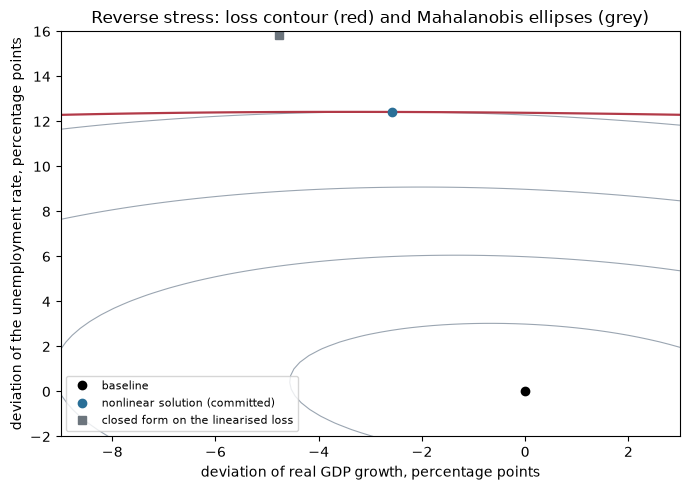

In [10]:
# Draw the Mahalanobis ellipses, the contour where the net loss equals the threshold, and the two solutions
gx, gy = np.linspace(-9, 3, 61), np.linspace(-2, 16, 61)
grid_loss = np.array([[net_loss([a, b]) for a in gx] for b in gy])
precision = np.linalg.inv(cov)
distance_grid = np.sqrt(precision[0, 0] * gx[None, :] ** 2 + 2 * precision[0, 1] * gx[None, :] * gy[:, None] + precision[1, 1] * gy[:, None] ** 2)
fig, ax = plt.subplots(figsize=(7, 5))
ax.contour(gx, gy, distance_grid, levels=[2, 4, 6, round(best.distance, 3)], colors="#9aa5b1", linewidths=0.8)
ax.contour(gx, gy, grid_loss, levels=[threshold], colors="#b23a48", linewidths=1.6)
ax.plot([0], [0], "ko", label="baseline")
ax.plot(*best.x_star, "o", color="#2a6f97", label="nonlinear solution (committed)")
ax.plot(*linear.x_star, "s", color="#6c757d", label="closed form on the linearised loss")
ax.set_xlabel("deviation of real GDP growth, percentage points")
ax.set_ylabel("deviation of the unemployment rate, percentage points")
ax.set_title("Reverse stress: loss contour (red) and Mahalanobis ellipses (grey)")
ax.legend(fontsize=8, loc="lower left")
fig.tight_layout()
plt.show()

- **The failure point is a CET1 ratio of 9.0625 percent** (the legal stack), 1.9375 points of RWA below the 11.0 percent start: a loss threshold of **CLP 145,174.0 million**, equal to the committed one. The two factors have standard deviations of 2.28 (GDP growth) and 1.51 (unemployment) points and a correlation of -0.147; the engine refuses a covariance that is not positive definite.
- **At the baseline the net loss is -322,940**: the baseline PPNR over three years (441,263) exceeds the losses, so the bank is CLP 468,114 million of net loss away from the failure point and "no stress" is not the question here.
- **The satellites make unemployment the dominant factor.** The gradient of the net loss at the baseline is -1,055 CLP million per point of GDP growth and +29,244 per point of unemployment, about 28 times larger.
- **The linearised problem is solved in closed form** (`x*` = -4.78 points of growth and +15.84 of unemployment, distance 10.48), but the true loss at that scenario is 317,699, 2.2 times the threshold: the probit link is convex, so the linear closed form overshoots and the true scenario is closer.
- **The nonlinear solution is a persistent deviation of -2.58 points of GDP growth and +12.42 of unemployment** ($z^* = (-1.13, 8.20)$, distance 8.205019), equal to the committed one to the digit, with a loss that misses the threshold by 4.2e-14 in relative terms. Three of the four starts converged, as in the committed document, and the fourth stopped at the same distance to twelve digits. The plausibility is 2.4e-15, equivalent to 7.8 standard deviations of a single normal variable.
- **The solution check is green** with three converged starts (statistic 4.2e-14, metric 0, the committed row), turns red when a start at 90 percent of the solution's distance is planted, and returns `not_evaluated` with only two starts.
- **The scenario that breaks the bank is 2.3 times the unemployment peak of the Federal Reserve's severely adverse scenario (5.5 points) and 2.4 times that of the global financial crisis (5.1 points)**, held for three years.

What this notebook does not show: the loss is a floor (market and operational risk carry only their expected loss) and its PPNR is a labelled row on assumed ratios, so the distance is a property of this model and its inputs; the satellites it runs on fail their own back-cast (notebook 07), which is a reason to read the distance as a statement about the satellites; and the empirical-likelihood estimator of Glasserman, Kang and Kang is not in the engine.

## Summary

- A reverse stress test starts from the failure and asks for the most plausible scenario that reaches it; the case's formal statement is the minimum Mahalanobis distance scenario on the loss surface, Contraste's formulation and not regulatory text.
- The failure point is CET1 at the Chilean legal minimum stack at the end of the three years; the threshold is the headroom of CET1 over it, and the loss is the three-year loss net of the baseline PPNR.
- For a linear loss the solution is closed form; the case's loss is nonlinear through the probit link, so the engine solves it numerically from several starts and a check refuses a solution that misses the threshold or has a closer start.
- The scenario that breaks the bank is far beyond any stress in the record: it needs a persistent shift of unemployment more than twice the Federal Reserve's severely adverse peak and a plausibility around $10^{-15}$ under the factor model, which says more about the bank's resilience in this synthetic case, and about what its inputs omit, than about the economy.

**What to try next.** Change the CET1 share of Pillar 2 in the stack of step 1 and watch the threshold and the distance move; then continue with notebook 07, which validates the aggregation and stress components with the engine's test batteries.

## References

- Glasserman, P., Kang, C. and Kang, W. (2015), Stress scenario selection by empirical likelihood, Quantitative Finance 15(1). https://doi.org/10.1080/14697688.2014.926019
- Dossiers 01 (J.4, the reverse stress formulation and EBA/GL/2018/04) and 05 (H.5, reverse stress testing) of the persisted Contraste research, as summarised in the SDD's research basis.
- This repository: `docs/contracts/engine/stress-api.md` (the reverse-stress functions) and `docs/design/features/c18/requirements.md` (CT-1815 and CT-1822).